<a href="https://colab.research.google.com/github/aranavkumar/Veloura/blob/main/04_Veloura_Diagnosis_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================
# VELOURA - PHASE 4
# DIAGNOSIS AGENT ENVIRONMENT SETUP
# ==========================================

from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import random
import numpy as np
import pandas as pd
import torch
import torchvision
import sklearn
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Project paths
PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

TRAIN_IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "datasets/training/extracted/Health/training/images"
)

TRAIN_METADATA_PATH = os.path.join(
    PROJECT_ROOT,
    "datasets/training/extracted/Health/training/metadata.csv"
)

MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "models/checkpoints"
)

FINAL_MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "models/final_models"
)

REPORT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports/model_evaluation"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True)

# Load training metadata
train_metadata = pd.read_csv(TRAIN_METADATA_PATH)

# Seven classes
CLASS_NAMES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

NUM_CLASSES = len(CLASS_NAMES)

print("=" * 55)
print("VELOURA - DIAGNOSIS AGENT ENVIRONMENT")
print("=" * 55)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nTraining images:", len(train_metadata))
print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)

print("\nGPU AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU. Training will be slower.")

print("\nTraining image folder exists:",
      os.path.isdir(TRAIN_IMAGE_DIR))

print("Metadata loaded:", len(train_metadata) == 7762)

print("\nDiagnosis Agent environment configured!")
print("=" * 55)


Mounted at /content/drive
VELOURA - DIAGNOSIS AGENT ENVIRONMENT
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Scikit-learn: 1.6.1

Training images: 7762
Number of classes: 7
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

GPU AVAILABLE: True
GPU: Tesla T4

Training image folder exists: True
Metadata loaded: True

Diagnosis Agent environment configured!


In [ ]:

import torch
import torchvision.models as models

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )

# Check EfficientNet-B0 availability
model_test = models.efficientnet_b0(weights=None)

print("\nEfficientNet-B0 loaded successfully!")
print("Model output classes before modification:",
      model_test.classifier[1].out_features)

del model_test

print("\nDiagnosis Agent model architecture is available.")


Selected device: cuda
GPU name: Tesla T4
GPU memory: 14.56 GB

EfficientNet-B0 loaded successfully!
Model output classes before modification: 1000

Diagnosis Agent model architecture is available.


In [ ]:

from sklearn.model_selection import StratifiedGroupKFold

# Work on a clean copy
df = train_metadata.copy()

# Confirm each image has one diagnosis
assert df["image_id"].is_unique, "Duplicate image IDs found"
assert df["lesion_id"].notna().all(), "Missing lesion IDs found"

# Check whether each lesion has only one diagnosis
labels_per_lesion = df.groupby("lesion_id")["dx"].nunique()

print("Lesions with multiple diagnosis labels:",
      (labels_per_lesion > 1).sum())

if (labels_per_lesion > 1).any():
    raise ValueError(
        "Some lesion IDs have multiple diagnosis labels. "
        "Investigate before splitting."
    )

# Stratified group split
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X=df,
        y=df["dx"],
        groups=df["lesion_id"]
    )
)

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
val_df = df.iloc[val_idx].copy().reset_index(drop=True)

# Verify lesion separation
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])

overlap = train_lesions.intersection(val_lesions)

print("\n========== DATA SPLIT RESULTS ==========")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

print("Training lesions:", len(train_lesions))
print("Validation lesions:", len(val_lesions))

print("Overlapping lesions:", len(overlap))

print("\nTRAINING CLASS DISTRIBUTION:")
print(train_df["dx"].value_counts().reindex(CLASS_NAMES))

print("\nVALIDATION CLASS DISTRIBUTION:")
print(val_df["dx"].value_counts().reindex(CLASS_NAMES))

assert len(overlap) == 0, "Lesion leakage detected!"
assert set(train_df["dx"]) == set(CLASS_NAMES)
assert set(val_df["dx"]) == set(CLASS_NAMES)

print("\nSUCCESS: Lesion-aware split verified!")


Lesions with multiple diagnosis labels: 0

========== DATA SPLIT RESULTS ==========
Training images: 6227
Validation images: 1535
Training lesions: 4652
Validation lesions: 1163
Overlapping lesions: 0

TRAINING CLASS DISTRIBUTION:
dx
akiec     186
bcc       296
bkl       711
df         70
mel       690
nv       4185
vasc       89
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION:
dx
akiec      63
bcc       104
bkl       137
df         18
mel       166
nv       1027
vasc       20
Name: count, dtype: int64

SUCCESS: Lesion-aware split verified!


In [ ]:

SPLIT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports",
    "model_evaluation"
)

os.makedirs(SPLIT_DIR, exist_ok=True)

train_df.to_csv(
    os.path.join(SPLIT_DIR, "diagnosis_train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(SPLIT_DIR, "diagnosis_validation_split.csv"),
    index=False
)

print("Training split saved!")
print("Validation split saved!")
print("Location:", SPLIT_DIR)


Training split saved!
Validation split saved!
Location: /content/drive/MyDrive/Veloura_Project/reports/model_evaluation


In [ ]:

import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Reload saved splits (also works after a runtime restart)
SPLIT_DIR = os.path.join(
    PROJECT_ROOT, "reports", "model_evaluation"
)

train_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "diagnosis_train_split.csv")
)
val_df = pd.read_csv(
    os.path.join(SPLIT_DIR, "diagnosis_validation_split.csv")
)

# Confirm the class-to-number mapping
class_to_idx = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

print("Class mapping:", class_to_idx)

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations prepared successfully!")


Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Image transformations prepared successfully!


In [ ]:

class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_id = str(row["image_id"])
        image_path = os.path.join(
            self.image_dir, image_id + ".jpg"
        )

        image = Image.open(image_path).convert("RGB")
        label = class_to_idx[row["dx"]]

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = SkinLesionDataset(
    train_df, TRAIN_IMAGE_DIR, train_transform
)

val_dataset = SkinLesionDataset(
    val_df, TRAIN_IMAGE_DIR, val_transform
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Inspect one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in first batch:", labels[:10].tolist())

assert images.shape[1:] == (3, 224, 224)
assert len(labels) == BATCH_SIZE

print("\nSUCCESS: Data pipeline is working!")


Training batches: 195
Validation batches: 48
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in first batch: [5, 5, 5, 2, 2, 5, 5, 0, 5, 4]

SUCCESS: Data pipeline is working!


In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Load EfficientNet-B0 with ImageNet pretrained weights
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

# Freeze the feature extractor for initial training
for param in model.features.parameters():
    param.requires_grad = False

# Replace the final classification layer
input_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    input_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

print("EfficientNet-B0 loaded successfully!")
print("Number of output classes:", NUM_CLASSES)
print("Device:", DEVICE)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 200MB/s]

EfficientNet-B0 loaded successfully!
Number of output classes: 7
Device: cuda
Trainable parameters: 8967


In [ ]:

import numpy as np

class_counts = (
    train_df["dx"]
    .value_counts()
    .reindex(CLASS_NAMES)
)

class_weights = 1.0 / np.sqrt(class_counts.values.astype(float))
class_weights = class_weights / class_weights.mean()

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

print("Class counts:")
print(class_counts)

print("\nClass weights:")
for class_name, weight in zip(CLASS_NAMES, class_weights):
    print(f"{class_name}: {weight:.3f}")

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

print("\nWeighted loss function prepared!")



Class counts:
dx
akiec     186
bcc       296
bkl       711
df         70
mel       690
nv       4185
vasc       89
Name: count, dtype: int64

Class weights:
akiec: 1.146
bcc: 0.908
bkl: 0.586
df: 1.868
mel: 0.595
nv: 0.242
vasc: 1.656

Weighted loss function prepared!


In [ ]:

import torch.optim as optim

# Only train parameters that are not frozen
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 8
BEST_MODEL_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "veloura_efficientnet_b0_best.pth"
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Planned epochs:", EPOCHS)
print("Checkpoint path:", BEST_MODEL_PATH)


Optimizer: AdamW
Learning rate: 0.001
Planned epochs: 8
Checkpoint path: /content/drive/MyDrive/Veloura_Project/models/final_models/veloura_efficientnet_b0_best.pth


In [ ]:

from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import copy
import time

# Mixed precision helps reduce GPU memory usage on the T4
use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

history = []
best_val_f1 = -1.0
best_epoch = 0

for epoch in range(EPOCHS):
    start_time = time.time()

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    train_losses = []
    train_true = []
    train_pred = []

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} - Training"
    )

    for images, labels in progress:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions = outputs.argmax(dim=1)

        train_losses.append(loss.item())
        train_true.extend(labels.detach().cpu().tolist())
        train_pred.extend(predictions.detach().cpu().tolist())

        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = float(np.mean(train_losses))
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro",
        zero_division=0
    )

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_losses = []
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{EPOCHS} - Validation"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            val_losses.append(loss.item())
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss = float(np.mean(val_losses))
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro",
        zero_division=0
    )

    epoch_time = time.time() - start_time

    metrics = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "time_seconds": epoch_time
    }

    history.append(metrics)

    print(f"\n========== EPOCH {epoch + 1}/{EPOCHS} ==========")
    print(f"Training loss:    {train_loss:.4f}")
    print(f"Training accuracy:{train_acc:.4f}")
    print(f"Training macro F1:{train_f1:.4f}")
    print(f"Validation loss:  {val_loss:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Validation macro F1: {val_f1:.4f}")
    print(f"Time: {epoch_time:.1f} seconds")

    # Save the model with the best validation macro F1
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch + 1

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "class_to_idx": class_to_idx,
            "validation_macro_f1": best_val_f1
        }, BEST_MODEL_PATH)

        print("New best checkpoint saved!")

    print()

# Save training history
history_df = pd.DataFrame(history)

history_path = os.path.join(
    REPORT_DIR,
    "diagnosis_training_history.csv"
)

history_df.to_csv(history_path, index=False)

print("\n========== TRAINING COMPLETE ==========")
print("Best epoch:", best_epoch)
print("Best validation macro F1:", round(best_val_f1, 4))
print("Best model:", BEST_MODEL_PATH)
print("Training history:", history_path)


Epoch 1/8 - Training:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 1/8 - Validation:   0%|          | 0/48 [00:00<?, ?it/s]


========== EPOCH 1/8 ==========
Training loss:    1.3238
Training accuracy:0.6811
Training macro F1:0.3399
Validation loss:  1.0105
Validation accuracy: 0.6586
Validation macro F1: 0.3837
Time: 2128.4 seconds
New best checkpoint saved!



Epoch 2/8 - Training:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 2/8 - Validation:   0%|          | 0/48 [00:00<?, ?it/s]


========== EPOCH 2/8 ==========
Training loss:    1.0828
Training accuracy:0.7159
Training macro F1:0.4838
Validation loss:  0.9660
Validation accuracy: 0.6619
Validation macro F1: 0.4176
Time: 75.0 seconds
New best checkpoint saved!



... (16 outputs left out)


========== EPOCH 7/8 ==========
Training loss:    0.8923
Training accuracy:0.7368
Training macro F1:0.5470
Validation loss:  0.8285
Validation accuracy: 0.6951
Validation macro F1: 0.4582
Time: 73.9 seconds
New best checkpoint saved!



Epoch 8/8 - Training:   0%|          | 0/195 [00:00<?, ?it/s]

Epoch 8/8 - Validation:   0%|          | 0/48 [00:00<?, ?it/s]


========== EPOCH 8/8 ==========
Training loss:    0.8674
Training accuracy:0.7445
Training macro F1:0.5624
Validation loss:  0.7840
Validation accuracy: 0.7173
Validation macro F1: 0.4787
Time: 74.0 seconds
New best checkpoint saved!


========== TRAINING COMPLETE ==========
Best epoch: 8
Best validation macro F1: 0.4787
Best model: /content/drive/MyDrive/Veloura_Project/models/final_models/veloura_efficientnet_b0_best.pth
Training history: /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_training_history.csv


In [ ]:

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)
import matplotlib.pyplot as plt

# Load the best saved checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Saved validation macro F1:", checkpoint["validation_macro_f1"])

# Generate validation predictions
all_true = []
all_pred = []
all_probabilities = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Evaluating validation set"):
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda"
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        all_true.extend(labels.numpy().tolist())
        all_pred.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_probabilities = np.array(all_probabilities)

print("\nValidation accuracy:",
      round(accuracy_score(all_true, all_pred), 4))

print("Validation macro F1:",
      round(f1_score(all_true, all_pred, average="macro"), 4))

print("\nCLASSIFICATION REPORT:\n")
print(classification_report(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))


Loaded best checkpoint from epoch: 8
Saved validation macro F1: 0.47871053674501646


Evaluating validation set:   0%|          | 0/48 [00:00<?, ?it/s]


Validation accuracy: 0.7173
Validation macro F1: 0.4787

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

       akiec     0.4478    0.4762    0.4615        63
         bcc     0.4745    0.6250    0.5394       104
         bkl     0.4451    0.5620    0.4968       137
          df     0.1176    0.1111    0.1143        18
         mel     0.4011    0.4398    0.4195       166
          nv     0.9055    0.8208    0.8611      1027
        vasc     0.3929    0.5500    0.4583        20

    accuracy                         0.7173      1535
   macro avg     0.4549    0.5121    0.4787      1535
weighted avg     0.7459    0.7173    0.7286      1535



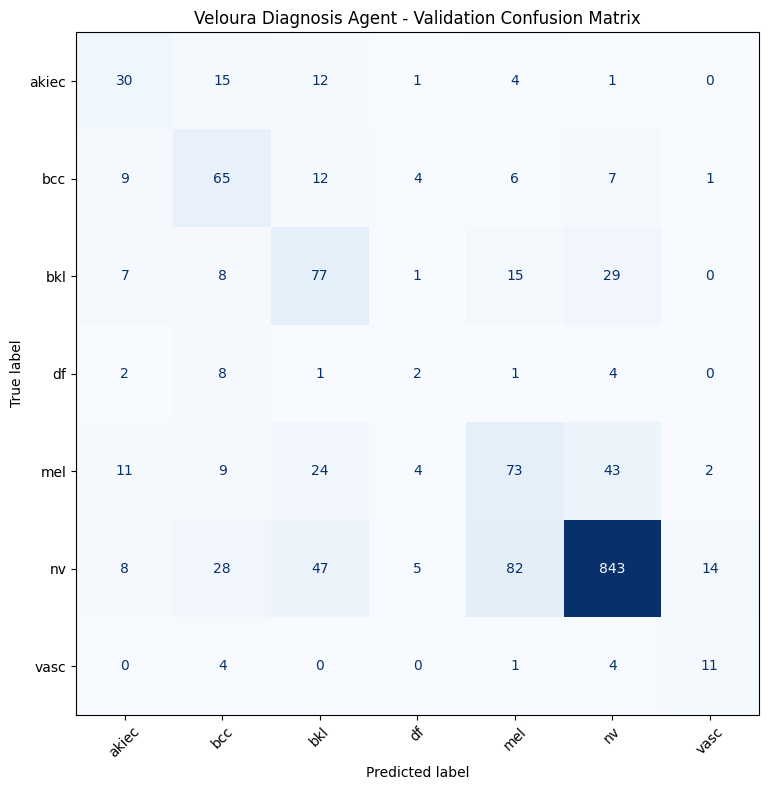

Confusion matrix saved: /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_validation_confusion_matrix.csv


In [ ]:

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Veloura Diagnosis Agent - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_path = os.path.join(
    REPORT_DIR,
    "diagnosis_validation_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)

print("Confusion matrix saved:", cm_path)


In [ ]:

prediction_df = val_df[["image_id", "lesion_id", "dx"]].copy()

prediction_df["true_label"] = [
    CLASS_NAMES[i] for i in all_true
]

prediction_df["predicted_label"] = [
    CLASS_NAMES[i] for i in all_pred
]

prediction_df["correct"] = (
    prediction_df["true_label"] ==
    prediction_df["predicted_label"]
)

prediction_df["confidence"] = all_probabilities.max(axis=1)

for i, class_name in enumerate(CLASS_NAMES):
    prediction_df[f"prob_{class_name}"] = all_probabilities[:, i]

prediction_path = os.path.join(
    REPORT_DIR,
    "diagnosis_validation_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)

print("Total validation predictions:", len(prediction_df))
print("Correct predictions:", int(prediction_df["correct"].sum()))
print("Incorrect predictions:", int((~prediction_df["correct"]).sum()))
print("Predictions saved:", prediction_path)

print("\nLowest-performing classes should be examined in the classification report.")


Total validation predictions: 1535
Correct predictions: 1101
Incorrect predictions: 434
Predictions saved: /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_validation_predictions.csv

Lowest-performing classes should be examined in the classification report.


In [ ]:

# Start from the best baseline checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Freeze all feature layers first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the final three feature blocks
for param in model.features[6:].parameters():
    param.requires_grad = True

# Keep the classification head trainable
for param in model.classifier.parameters():
    param.requires_grad = True

print("Fine-tuning configuration:")
print("Frozen feature blocks: 0 to 5")
print("Unfrozen feature blocks: 6 to 8")
print("Classification head: trainable")

trainable_count = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_count)

model = model.to(DEVICE)


Fine-tuning configuration:
Frozen feature blocks: 0 to 5
Unfrozen feature blocks: 6 to 8
Classification head: trainable
Trainable parameters: 3164707


In [ ]:

# Use a smaller learning rate for pretrained feature layers
optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features[6:].parameters(),
            "lr": 0.00001
        },
        {
            "params": model.classifier.parameters(),
            "lr": 0.0001
        }
    ],
    weight_decay=0.0001
)

FINE_TUNE_EPOCHS = 5

FINE_TUNED_MODEL_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "veloura_efficientnet_b0_finetuned_best.pth"
)

print("Fine-tuning optimizer prepared!")
print("Feature learning rate: 0.00001")
print("Classifier learning rate: 0.0001")
print("Fine-tuning epochs:", FINE_TUNE_EPOCHS)


Fine-tuning optimizer prepared!
Feature learning rate: 0.00001
Classifier learning rate: 0.0001
Fine-tuning epochs: 5


In [ ]:

fine_tune_history = []
best_finetune_f1 = -1.0
best_finetune_epoch = 0

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)

for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    # TRAINING
    model.train()

    train_losses = []
    train_true = []
    train_pred = []

    for images, labels in tqdm(
        train_loader,
        desc=f"Fine-tune {epoch + 1}/{FINE_TUNE_EPOCHS}"
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions = outputs.argmax(dim=1)

        train_losses.append(loss.item())
        train_true.extend(labels.cpu().tolist())
        train_pred.extend(predictions.detach().cpu().tolist())

    train_loss = float(np.mean(train_losses))
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(
        train_true, train_pred,
        average="macro",
        zero_division=0
    )

    # VALIDATION
    model.eval()

    val_losses = []
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            val_losses.append(loss.item())
            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss = float(np.mean(val_losses))
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro",
        zero_division=0
    )

    epoch_time = time.time() - start_time

    metrics = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "time_seconds": epoch_time
    }

    fine_tune_history.append(metrics)

    print(f"\nFine-tuning epoch {epoch + 1}")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Training accuracy: {train_acc:.4f}")
    print(f"Training macro F1: {train_f1:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Validation macro F1: {val_f1:.4f}")
    print(f"Time: {epoch_time:.1f} seconds")

    if val_f1 > best_finetune_f1:
        best_finetune_f1 = val_f1
        best_finetune_epoch = epoch + 1

        torch.save({
            "epoch": best_finetune_epoch,
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "class_to_idx": class_to_idx,
            "validation_macro_f1": best_finetune_f1
        }, FINE_TUNED_MODEL_PATH)

        print("New best fine-tuned checkpoint saved!")

# Save experiment history
fine_tune_df = pd.DataFrame(fine_tune_history)

fine_tune_history_path = os.path.join(
    REPORT_DIR,
    "diagnosis_finetuning_history.csv"
)

fine_tune_df.to_csv(
    fine_tune_history_path,
    index=False
)

print("\n========== FINE-TUNING COMPLETE ==========")
print("Best fine-tuning epoch:", best_finetune_epoch)
print("Best fine-tuning macro F1:", round(best_finetune_f1, 4))
print("Baseline macro F1:", round(0.47871053674501646, 4))
print("Fine-tuned checkpoint:", FINE_TUNED_MODEL_PATH)


Fine-tune 1/5:   0%|          | 0/195 [00:00<?, ?it/s]


Fine-tuning epoch 1
Training loss: 0.8525
Training accuracy: 0.7569
Training macro F1: 0.5830
Validation loss: 0.7834
Validation accuracy: 0.7127
Validation macro F1: 0.4896
Time: 79.3 seconds
New best fine-tuned checkpoint saved!


Fine-tune 2/5:   0%|          | 0/195 [00:00<?, ?it/s]


Fine-tuning epoch 2
Training loss: 0.8076
Training accuracy: 0.7647
Training macro F1: 0.5950
Validation loss: 0.7723
Validation accuracy: 0.7147
Validation macro F1: 0.5164
Time: 73.0 seconds
New best fine-tuned checkpoint saved!


Fine-tune 3/5:   0%|          | 0/195 [00:00<?, ?it/s]


Fine-tuning epoch 3
Training loss: 0.7827
Training accuracy: 0.7683
Training macro F1: 0.6138
Validation loss: 0.7581
Validation accuracy: 0.7349
Validation macro F1: 0.5114
Time: 73.5 seconds


Fine-tune 4/5:   0%|          | 0/195 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cbcc8698c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7cbcc8698c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Fine-tuning epoch 4
Training loss: 0.7664
Training accuracy: 0.7729
Training macro F1: 0.6228
Validation loss: 0.7173
Validation accuracy: 0.7427
Validation macro F1: 0.5287
Time: 74.4 seconds
New best fine-tuned checkpoint saved!


Fine-tune 5/5:   0%|          | 0/195 [00:00<?, ?it/s]


Fine-tuning epoch 5
Training loss: 0.7368
Training accuracy: 0.7784
Training macro F1: 0.6311
Validation loss: 0.6968
Validation accuracy: 0.7479
Validation macro F1: 0.5410
Time: 73.7 seconds
New best fine-tuned checkpoint saved!

========== FINE-TUNING COMPLETE ==========
Best fine-tuning epoch: 5
Best fine-tuning macro F1: 0.541
Baseline macro F1: 0.4787
Fine-tuned checkpoint: /content/drive/MyDrive/Veloura_Project/models/final_models/veloura_efficientnet_b0_finetuned_best.pth


In [ ]:

checkpoint = torch.load(
    FINE_TUNED_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded fine-tuned model from epoch:", checkpoint["epoch"])
print("Saved validation macro F1:", checkpoint["validation_macro_f1"])

fine_true = []
fine_pred = []
fine_probabilities = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader,
        desc="Evaluating fine-tuned model"
    ):
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)
        predictions = probabilities.argmax(dim=1)

        fine_true.extend(labels.numpy().tolist())
        fine_pred.extend(predictions.cpu().numpy().tolist())
        fine_probabilities.extend(probabilities.cpu().numpy().tolist())

fine_true = np.array(fine_true)
fine_pred = np.array(fine_pred)
fine_probabilities = np.array(fine_probabilities)

fine_accuracy = accuracy_score(fine_true, fine_pred)
fine_macro_f1 = f1_score(
    fine_true, fine_pred,
    average="macro",
    zero_division=0
)

print("\nFINE-TUNED VALIDATION RESULTS")
print("Accuracy:", round(fine_accuracy, 4))
print("Macro F1:", round(fine_macro_f1, 4))

print("\nCLASSIFICATION REPORT:\n")
print(classification_report(
    fine_true,
    fine_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))


Loaded fine-tuned model from epoch: 5
Saved validation macro F1: 0.541032539332517


Evaluating fine-tuned model:   0%|          | 0/48 [00:00<?, ?it/s]


FINE-TUNED VALIDATION RESULTS
Accuracy: 0.7479
Macro F1: 0.541

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

       akiec     0.5556    0.4762    0.5128        63
         bcc     0.5470    0.6154    0.5792       104
         bkl     0.4381    0.6715    0.5303       137
          df     0.2308    0.1667    0.1935        18
         mel     0.4487    0.4217    0.4348       166
          nv     0.9187    0.8471    0.8815      1027
        vasc     0.5000    0.9500    0.6552        20

    accuracy                         0.7479      1535
   macro avg     0.5198    0.5927    0.5410      1535
weighted avg     0.7714    0.7479    0.7552      1535



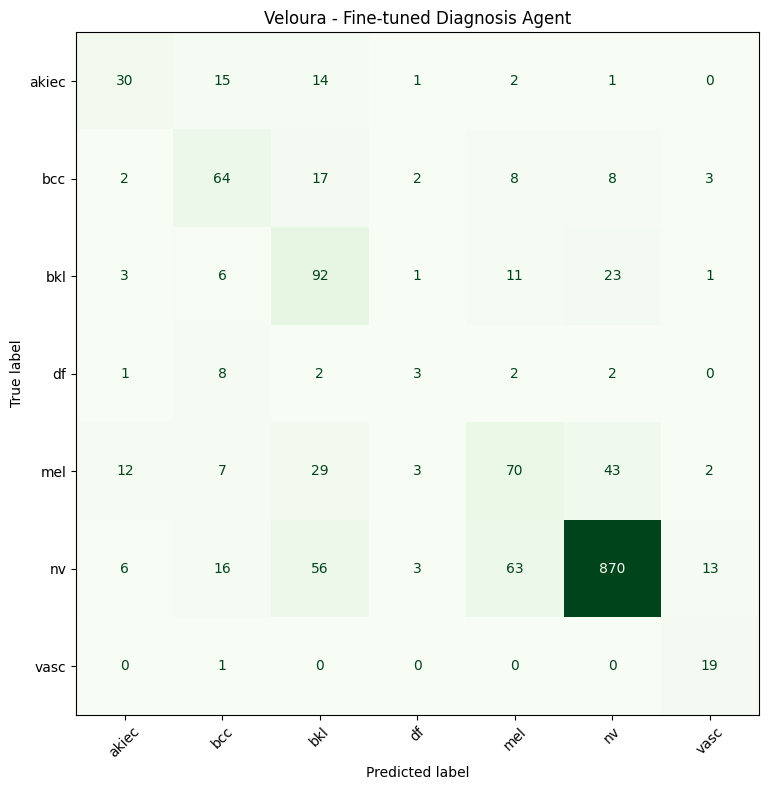

Fine-tuned confusion matrix saved: /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_finetuned_confusion_matrix.csv


In [ ]:

fine_cm = confusion_matrix(
    fine_true,
    fine_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=fine_cm,
    display_labels=CLASS_NAMES
)

display.plot(
    ax=ax,
    cmap="Greens",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Veloura - Fine-tuned Diagnosis Agent")
plt.tight_layout()
plt.show()

fine_cm_df = pd.DataFrame(
    fine_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

fine_cm_path = os.path.join(
    REPORT_DIR,
    "diagnosis_finetuned_confusion_matrix.csv"
)

fine_cm_df.to_csv(fine_cm_path)

print("Fine-tuned confusion matrix saved:", fine_cm_path)


In [ ]:

fine_prediction_df = val_df[
    ["image_id", "lesion_id", "dx"]
].copy()

fine_prediction_df["true_label"] = [
    CLASS_NAMES[i] for i in fine_true
]

fine_prediction_df["predicted_label"] = [
    CLASS_NAMES[i] for i in fine_pred
]

fine_prediction_df["correct"] = (
    fine_prediction_df["true_label"] ==
    fine_prediction_df["predicted_label"]
)

fine_prediction_df["confidence"] = (
    fine_probabilities.max(axis=1)
)

for i, class_name in enumerate(CLASS_NAMES):
    fine_prediction_df[f"prob_{class_name}"] = (
        fine_probabilities[:, i]
    )

fine_prediction_path = os.path.join(
    REPORT_DIR,
    "diagnosis_finetuned_validation_predictions.csv"
)

fine_prediction_df.to_csv(
    fine_prediction_path,
    index=False
)

print("Total predictions:", len(fine_prediction_df))
print("Correct:", int(fine_prediction_df["correct"].sum()))
print("Incorrect:", int((~fine_prediction_df["correct"]).sum()))
print("Saved:", fine_prediction_path)


Total predictions: 1535
Correct: 1148
Incorrect: 387
Saved: /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_finetuned_validation_predictions.csv


In [ ]:

import json
import shutil
from datetime import datetime

# Selected model: fine-tuned EfficientNet-B0
SELECTED_MODEL_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "veloura_diagnosis_agent_final.pth"
)

shutil.copy2(
    FINE_TUNED_MODEL_PATH,
    SELECTED_MODEL_PATH
)

diagnosis_config = {
    "agent_name": "Veloura Diagnosis Agent",
    "architecture": "EfficientNet-B0",
    "pretrained_weights": "ImageNet",
    "num_classes": NUM_CLASSES,
    "class_names": CLASS_NAMES,
    "input_size": [224, 224],
    "selected_checkpoint": SELECTED_MODEL_PATH,
    "validation_accuracy": float(fine_accuracy),
    "validation_macro_f1": float(fine_macro_f1),
    "validation_images": len(val_df),
    "best_epoch": int(checkpoint["epoch"]),
    "selection_basis": "Best validation macro F1",
    "created_at": datetime.now().isoformat(),
    "clinical_status": "Research prototype; not clinically validated"
}

CONFIG_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "diagnosis_agent_config.json"
)

with open(CONFIG_PATH, "w") as f:
    json.dump(diagnosis_config, f, indent=4)

print("Selected diagnosis model saved!")
print("Model:", SELECTED_MODEL_PATH)
print("Configuration:", CONFIG_PATH)
print("Validation accuracy:", round(fine_accuracy, 4))
print("Validation macro F1:", round(fine_macro_f1, 4))


Selected diagnosis model saved!
Model: /content/drive/MyDrive/Veloura_Project/models/final_models/veloura_diagnosis_agent_final.pth
Configuration: /content/drive/MyDrive/Veloura_Project/models/final_models/diagnosis_agent_config.json
Validation accuracy: 0.7479
Validation macro F1: 0.541


In [ ]:

required_files = [
    SELECTED_MODEL_PATH,
    CONFIG_PATH,
    os.path.join(
        REPORT_DIR,
        "diagnosis_training_history.csv"
    ),
    os.path.join(
        REPORT_DIR,
        "diagnosis_finetuning_history.csv"
    ),
    os.path.join(
        REPORT_DIR,
        "diagnosis_finetuned_confusion_matrix.csv"
    ),
    os.path.join(
        REPORT_DIR,
        "diagnosis_finetuned_validation_predictions.csv"
    )
]

print("DIAGNOSIS AGENT ARTIFACT VERIFICATION")
print("=" * 45)

all_exist = True

for path in required_files:
    exists = os.path.isfile(path)
    print(("OK" if exists else "MISSING"), path)
    all_exist = all_exist and exists

assert all_exist, "Some diagnosis artifacts are missing!"

print("\nSUCCESS: All required diagnosis artifacts verified.")


DIAGNOSIS AGENT ARTIFACT VERIFICATION
OK /content/drive/MyDrive/Veloura_Project/models/final_models/veloura_diagnosis_agent_final.pth
OK /content/drive/MyDrive/Veloura_Project/models/final_models/diagnosis_agent_config.json
OK /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_training_history.csv
OK /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_finetuning_history.csv
OK /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_finetuned_confusion_matrix.csv
OK /content/drive/MyDrive/Veloura_Project/reports/model_evaluation/diagnosis_finetuned_validation_predictions.csv

SUCCESS: All required diagnosis artifacts verified.
